In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.size'] = 14
mpl.rcParams['font.family'] = 'Arial'

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [14]:
data_path = '../data/short_alcohol_data/alcohol.csv'
df = pd.read_csv(data_path)

timestamps = df.index
data = pd.DataFrame([df[col] for col in df.columns if 'data_' in col]).transpose()

section1 = [1000, 1500]
section2 = [2500, 3000]

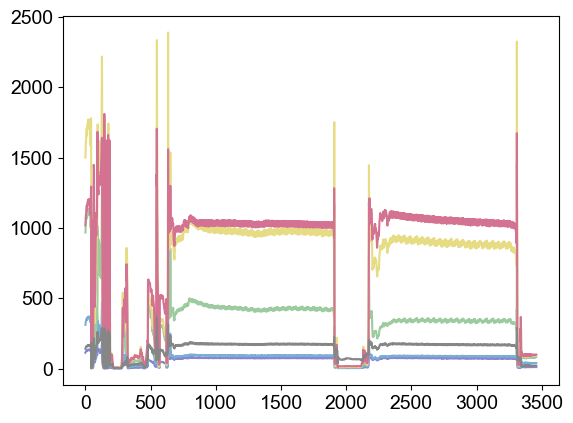

In [ ]:
for i, column in enumerate(data.columns):
    plt.plot(timestamps, data[column], color=colors[i], label=f'Channel {i+1}')

In [16]:
# find the mean and var of each channel at each section
means = []
vars = []
for i in range(data.shape[1]):
    means.append([
        data.iloc[section1[0]:section1[1], i].mean(),
        data.iloc[section2[0]:section2[1], i].mean(),
    ])
    vars.append([
        data.iloc[section1[0]:section1[1], i].var(),
        data.iloc[section2[0]:section2[1], i].var(),
    ])
means = np.array(means)
vars = np.array(vars)

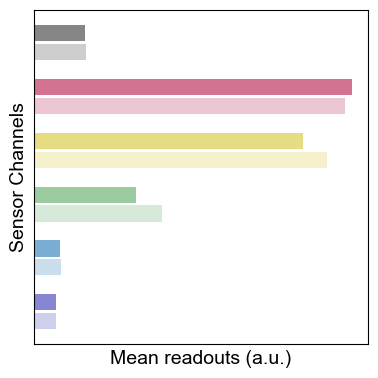

: 

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))

# Create y positions for the bars - each channel gets 2 bars with some spacing
y_positions = []
for i in range(6):
    y_positions.extend([i * 2, i * 2 + 0.7])

# Flatten the means array to match y_positions
section1_means = means[:, 0]  # Section 1 means for all channels
section2_means = means[:, 1]  # Section 2 means for all channels

# Interleave section1 and section2 means to match y_positions
bar_values = []
bar_colors = []
bar_alphas = []

for i in range(6):
    bar_values.extend([section1_means[i], section2_means[i]])
    bar_colors.extend([colors[i], colors[i]])
    bar_alphas.extend([0.4, 1.0])  # Top bar (section1) has lower alpha

# Create horizontal bars
bars = ax.barh(y_positions, bar_values, height=0.6, color=bar_colors, alpha=1.0)

# Set individual alpha values for each bar
for bar, alpha in zip(bars, bar_alphas):
    bar.set_alpha(alpha)

ax.set_xlabel('Mean readouts (a.u.)')
ax.set_ylabel('Sensor Channels')
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.savefig('../figures/fig1/short_alcohol_data_barplot.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()